# 03 Random Forest — Tala, Edrian

HeatCast NCR (simple version) · predicts `HeatLevelTomorrow`, the PAGASA heat level of the next day, for each of the 16 Metro Manila cities.

**Rules followed:** everything comes from `src/common.py`: the date split (train 2021-01-01 to 2024-12-27, test 2024-12-29 to 2025-12-28), the
5 time-ordered folds cut by whole days, `make_preprocess(scale=False)` (trees do not need scaling), the scoring (`cross_validate`,
`summarize`, `persistence_cv`) and `RANDOM_STATE = 42`. All 5 PAGASA levels are kept (no merging). **The test days are not used in this
notebook**; `final_test` is only run once, for the model the group picks (Section 6).

Metric used to choose: **`macro_f1_core3`** (macro F1 over Caution, Extreme Caution and Danger), reported next to Danger recall and
Danger precision.

In [1]:
import json, sys, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "common.py").exists():      # opened from notebooks/
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))
from common import *

OUT = ROOT / "results" / "random_forest"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format)
print("scikit-learn", sklearn.__version__, "| outputs ->", OUT.relative_to(ROOT))

scikit-learn 1.9.1 | outputs -> results/random_forest


## 1. Data, split and folds (shared)

In [2]:
df = load_data()
train, test = split_train_test(df)          # the test days are set aside and not used below
folds = make_folds(train)
print(f"all {len(df):,} rows | train {len(train):,} rows ({train.Date.min().date()} to {train.Date.max().date()}) | test {len(test):,} rows (not used)")
print("fold sizes (days learned from / days checked):", [(len(a) // 16, len(b) // 16) for a, b in folds])
train[TARGET].value_counts().to_frame("training rows")

all 29,168 rows | train 23,312 rows (2021-01-01 to 2024-12-27) | test 5,840 rows (not used)
fold sizes (days learned from / days checked): [(246, 242), (488, 242), (730, 242), (972, 242), (1214, 242)]


,training rows
HeatLevelTomorrow,
Extreme Caution,18304
Caution,3135
Danger,1833
Not Hazardous,40


## 2. Reference: the "copy today" rule on the same folds

Tomorrow's level = today's level. A model is only useful if it does better.

In [3]:
base = persistence_cv(train)
summarize(base)

,mean,sd
macro_f1,0.620,0.102
macro_f1_core3,0.679,0.051
accuracy,0.846,0.039
danger_recall,0.518,0.153
danger_precision,0.527,0.153


## 3. The model

`RandomForestClassifier` behind `make_preprocess(scale=False)`: the 5 weather numbers pass through unchanged and `City` becomes 16 yes/no
columns, learned from each fold's training days only. Settings varied (all scored on the same 5 folds):

* `max_depth`: 4, 8, 12 or no limit. How deep each tree may grow.
* `min_samples_leaf`: 5, 20 or 50. The smallest group of rows a leaf may hold. Larger values stop trees from copying single days; this
  matters here because the 16 cities of a day share much of the weather.
* `class_weight`: none or `"balanced"` (rare classes count more). Balanced weights are computed from each fold's training labels only.
* `n_estimators` (number of trees) is fixed at 200 for the grid and then checked at 100, 200 and 500 for the best setting.

Fixed: `max_features="sqrt"` (the default), `random_state=42`. `oob_score` is not used: out-of-bag rows are random rows from the same
period, so they are not a time-aware check; only the 5 time-ordered folds choose the settings.

In [4]:
def make_rf(max_depth=8, min_samples_leaf=5, class_weight=None, n_estimators=200):
    rf = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                class_weight=class_weight, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1)
    return make_pipeline(make_preprocess(scale=False), rf)


def run(**cfg):
    table = cross_validate(make_rf(**cfg), train)
    m, s = table.mean(), table.std(ddof=1)
    return {**cfg, **{f"{k}_mean": m[k] for k in table}, **{f"{k}_sd": s[k] for k in table}}, table

## 4. Tuning: depth × leaf size × class weight (24 settings, 200 trees)

In [5]:
rows = []
for cw in [None, "balanced"]:
    for d in [4, 8, 12, None]:
        for leaf in [5, 20, 50]:
            rows.append(run(max_depth=d, min_samples_leaf=leaf, class_weight=cw)[0])
grid = pd.DataFrame(rows)
grid["max_depth"] = grid["max_depth"].astype(object).where(grid["max_depth"].notna(), "none")
grid["class_weight"] = grid["class_weight"].fillna("none")
grid = grid.sort_values("macro_f1_core3_mean", ascending=False).reset_index(drop=True)
show = ["max_depth", "min_samples_leaf", "class_weight", "macro_f1_core3_mean", "macro_f1_core3_sd", "macro_f1_mean",
        "accuracy_mean", "danger_recall_mean", "danger_precision_mean"]
grid[show]

,max_depth,min_samples_leaf,class_weight,macro_f1_core3_mean,macro_f1_core3_sd,macro_f1_mean,accuracy_mean,danger_recall_mean,danger_precision_mean
0,12.000,5,balanced,0.650,0.042,0.586,0.793,0.650,0.397
1,none,5,balanced,0.644,0.048,0.579,0.803,0.597,0.412
2,none,20,balanced,0.639,0.029,0.576,0.766,0.771,0.361
3,8.000,5,balanced,0.637,0.030,0.574,0.771,0.724,0.363
4,12.000,20,balanced,0.633,0.028,0.571,0.763,0.758,0.355
5,8.000,20,balanced,0.628,0.027,0.566,0.756,0.755,0.343
6,none,50,balanced,0.624,0.033,0.563,0.745,0.781,0.333
7,12.000,50,balanced,0.622,0.030,0.561,0.744,0.782,0.333
8,8.000,50,balanced,0.622,0.030,0.560,0.744,0.782,0.335
9,4.000,5,balanced,0.606,0.030,0.548,0.728,0.760,0.320


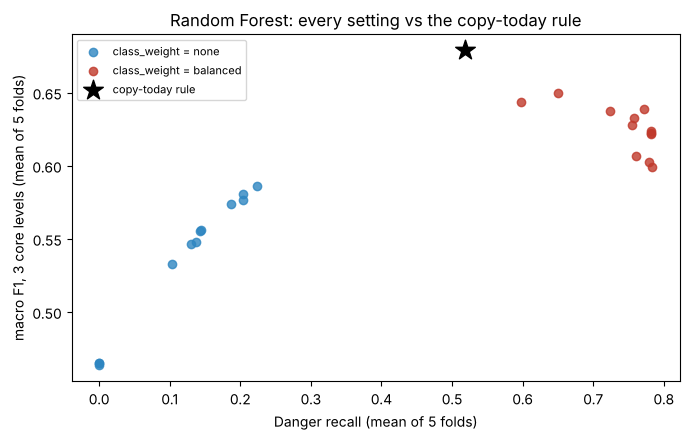

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for cw, color in [("none", "#2e86c1"), ("balanced", "#c0392b")]:
    g = grid[grid.class_weight == cw]
    ax.scatter(g.danger_recall_mean, g.macro_f1_core3_mean, color=color, label=f"class_weight = {cw}", alpha=.8)
b = summarize(base)["mean"]
ax.scatter([b["danger_recall"]], [b["macro_f1_core3"]], marker="*", s=220, color="black", label="copy-today rule", zorder=5)
ax.set_xlabel("Danger recall (mean of 5 folds)"); ax.set_ylabel("macro F1, 3 core levels (mean of 5 folds)")
ax.set_title("Random Forest: every setting vs the copy-today rule"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "figure_RF1_settings.png", dpi=200); plt.show()

## 5. Number of trees, for the best setting

More trees only lower the variance of a forest, so this is checked last. The best setting is the row with the highest mean
`macro_f1_core3`.

In [7]:
best = grid.iloc[0]
BEST = dict(max_depth=None if best.max_depth == "none" else int(best.max_depth),
            min_samples_leaf=int(best.min_samples_leaf), class_weight=None if best.class_weight == "none" else best.class_weight)
print("best of the 24:", BEST)
trees = pd.DataFrame([run(**BEST, n_estimators=n)[0] for n in [100, 200, 500]])
trees[["n_estimators", "macro_f1_core3_mean", "macro_f1_core3_sd", "macro_f1_mean", "accuracy_mean", "danger_recall_mean",
       "danger_precision_mean"]]

best of the 24: {'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': 'balanced'}


,n_estimators,macro_f1_core3_mean,macro_f1_core3_sd,macro_f1_mean,accuracy_mean,danger_recall_mean,danger_precision_mean
0,100,0.647,0.041,0.583,0.793,0.650,0.396
1,200,0.650,0.042,0.586,0.793,0.650,0.397
2,500,0.653,0.039,0.589,0.794,0.672,0.402


In [8]:
# keep the smallest forest whose core-3 macro F1 is within 0.002 of the best number of trees (smaller file, same skill)
top = trees.macro_f1_core3_mean.max()
N_TREES = int(trees[trees.macro_f1_core3_mean >= top - 0.002].n_estimators.min())
SELECTED = {**BEST, "n_estimators": N_TREES}
print("selected:", SELECTED)
sel_row, sel_folds = run(**SELECTED)
sel_folds.to_csv(OUT / "selected_cv_folds.csv")
extra = pd.DataFrame([run(**SELECTED)[0]]).assign(note="selected")
all_cfg = pd.concat([grid.assign(n_estimators=200), trees.assign(max_depth=trees.max_depth.astype(object).where(trees.max_depth.notna(), "none"),
                     class_weight=trees.class_weight.fillna("none"))], ignore_index=True).drop_duplicates(
    subset=["max_depth", "min_samples_leaf", "class_weight", "n_estimators"])
all_cfg.sort_values("macro_f1_core3_mean", ascending=False).to_csv(OUT / "cv_grid.csv", index=False)
sel_folds.round(3)

selected: {'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': 'balanced', 'n_estimators': 500}


,macro_f1,macro_f1_core3,accuracy,danger_recall,danger_precision
fold,,,,,
1,0.632,0.632,0.823,0.362,0.282
2,0.446,0.594,0.837,0.600,0.342
3,0.515,0.687,0.760,0.777,0.342
4,0.679,0.679,0.789,0.807,0.527
5,0.672,0.672,0.763,0.811,0.519


### Validation summary vs the copy-today rule (mean ± SD over the 5 folds)

In [9]:
metrics = ["macro_f1_core3", "macro_f1", "accuracy", "danger_recall", "danger_precision"]
pm = lambda t, m: f"{t[m].mean():.3f} ± {t[m].std(ddof=1):.3f}"
compare = pd.DataFrame({"Random Forest": [pm(sel_folds, m) for m in metrics],
                        "Copy today": [pm(base, m) for m in metrics]}, index=metrics)
display(compare)
diff = sel_folds[metrics] - base[metrics]
print("Random Forest minus copy-today, per fold:"); display(diff)
print("folds where the Random Forest is ahead:", (diff > 0).sum().to_dict(), "(of 5)")

,Random Forest,Copy today
macro_f1_core3,0.653 ± 0.039,0.679 ± 0.051
macro_f1,0.589 ± 0.103,0.620 ± 0.102
accuracy,0.794 ± 0.035,0.846 ± 0.039
danger_recall,0.672 ± 0.193,0.518 ± 0.153
danger_precision,0.402 ± 0.113,0.527 ± 0.153


Random Forest minus copy-today, per fold:


,macro_f1_core3,macro_f1,accuracy,danger_recall,danger_precision
fold,,,,,
1,-0.016,-0.016,-0.042,0.075,-0.029
2,-0.029,-0.061,-0.033,0.045,-0.197
3,-0.018,-0.013,-0.064,0.325,-0.110
4,-0.074,-0.074,-0.096,0.150,-0.178
5,0.007,0.007,-0.026,0.171,-0.108


folds where the Random Forest is ahead: {'macro_f1_core3': 1, 'macro_f1': 1, 'accuracy': 0, 'danger_recall': 5, 'danger_precision': 0} (of 5)


### Confusion matrix (out-of-fold predictions, all 5 folds pooled)

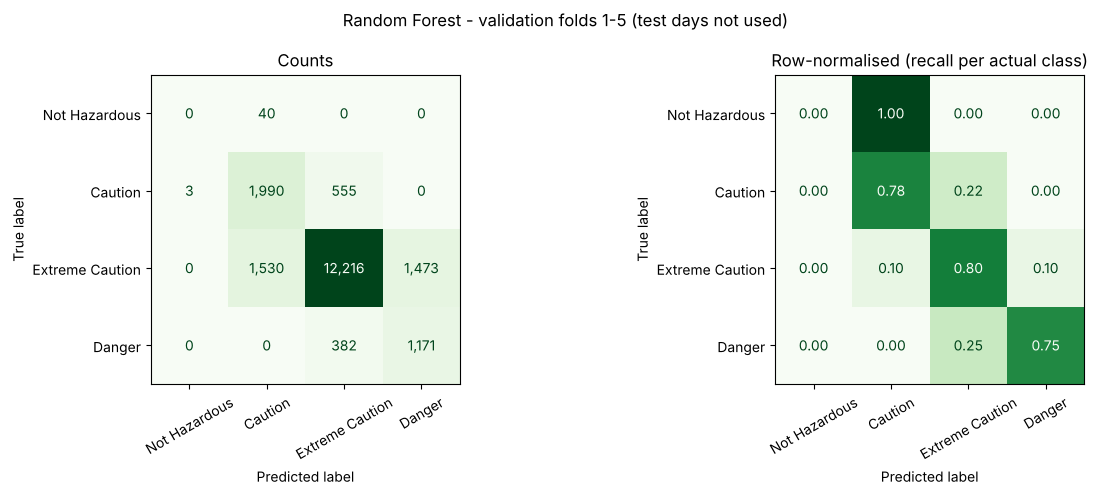

predicted,Not Hazardous,Caution,Extreme Caution,Danger
actual,,,,
Not Hazardous,0,40,0,0
Caution,3,1990,555,0
Extreme Caution,0,1530,12216,1473
Danger,0,0,382,1171


In [10]:
X, y = train[FEATURES], train[TARGET]
oof_true, oof_pred = [], []
for fit_idx, check_idx in folds:
    m = clone(make_rf(**SELECTED)).fit(X.iloc[fit_idx], y.iloc[fit_idx])
    oof_true.append(y.iloc[check_idx].to_numpy()); oof_pred.append(m.predict(X.iloc[check_idx]))
oof_true, oof_pred = np.concatenate(oof_true), np.concatenate(oof_pred)
used = [c for c in CLASSES if c in set(oof_true) | set(oof_pred)]
cm = pd.DataFrame(confusion_matrix(oof_true, oof_pred, labels=used), index=pd.Index(used, name="actual"), columns=pd.Index(used, name="predicted"))
cm.to_csv(OUT / "confusion_matrix.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm.to_numpy(), display_labels=used).plot(ax=axes[0], cmap="Greens", values_format=",d", colorbar=False)
axes[0].set_title("Counts")
ConfusionMatrixDisplay(cm.div(cm.sum(axis=1), axis=0).to_numpy(), display_labels=used).plot(ax=axes[1], cmap="Greens", values_format=".2f", colorbar=False)
axes[1].set_title("Row-normalised (recall per actual class)")
for ax in axes: ax.tick_params(axis="x", rotation=30)
fig.suptitle("Random Forest - validation folds 1-5 (test days not used)"); fig.tight_layout()
fig.savefig(OUT / "figure_RF2_confusion_matrix.png", dpi=200); plt.show()
cm

## 6. What the forest uses

The selected setting is refitted on the **training days only**. *Impurity importance* (from the fitted forest) favours inputs with many
distinct values, so *permutation importance* is the more reliable one: on the check block of the last fold, with a forest fitted on that fold's
training days, one input is shuffled and the drop in `macro_f1_core3` is measured. Inputs that carry similar information share credit.

In [11]:
final = make_rf(**SELECTED).fit(X, y)
names = final.named_steps["columntransformer"].get_feature_names_out()
imp = pd.Series(final.named_steps["randomforestclassifier"].feature_importances_, index=names).sort_values(ascending=False)
imp.rename("impurity_importance").to_csv(OUT / "impurity_importance.csv")

fit_idx, check_idx = folds[-1]
m5 = make_rf(**SELECTED).fit(X.iloc[fit_idx], y.iloc[fit_idx])
Xv, yv = X.iloc[check_idx], y.iloc[check_idx]
core3 = lambda est, X_, y_: f1_score(y_, est.predict(X_), labels=CORE_LEVELS, average="macro", zero_division=0)
perm = permutation_importance(m5, Xv, yv, scoring=core3, n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=Xv.columns).sort_values(ascending=False)
perm_imp.rename("permutation_core3_f1_drop").to_csv(OUT / "permutation_importance.csv")
display(pd.concat([imp.head(8).rename("impurity importance (city columns separate)")], axis=1))
display(perm_imp.to_frame("drop in core-3 macro F1 when shuffled (last fold)"))

,impurity importance (city columns separate)
numbers__HeatIndex_Max_Today,0.376
numbers__Temp_Min,0.216
numbers__Pressure_Mean,0.162
numbers__SolarRadiation_Total,0.145
numbers__Rainfall_Total,0.075
city__City_Navotas,0.004
city__City_Valenzuela,0.004
city__City_Malabon,0.004


,drop in core-3 macro F1 when shuffled (last fold)
HeatIndex_Max_Today,0.267
Temp_Min,0.086
SolarRadiation_Total,0.069
Pressure_Mean,0.023
City,0.011
Rainfall_Total,0.010


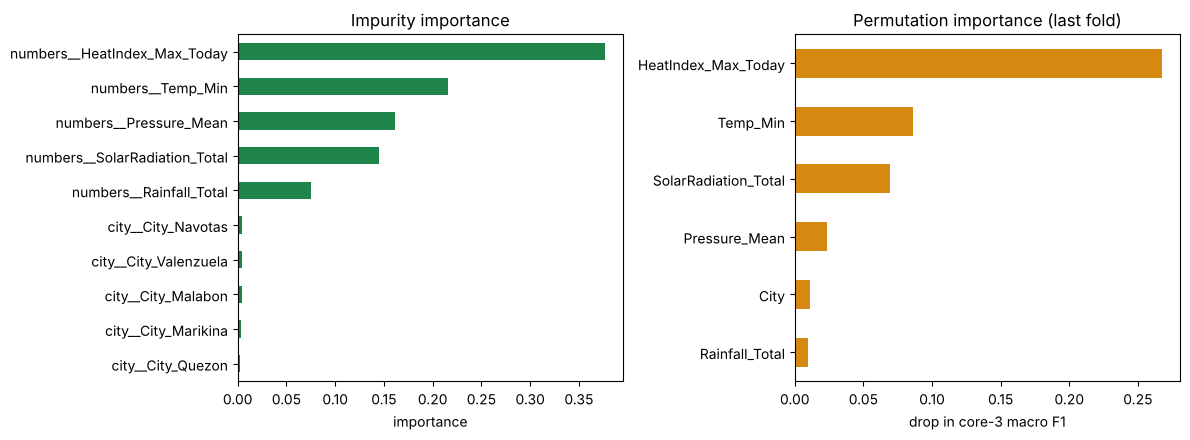

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
imp.head(10)[::-1].plot.barh(ax=axes[0], color="#1e8449"); axes[0].set_title("Impurity importance"); axes[0].set_xlabel("importance")
perm_imp[::-1].plot.barh(ax=axes[1], color="#d68910"); axes[1].set_title("Permutation importance (last fold)"); axes[1].set_xlabel("drop in core-3 macro F1")
fig.tight_layout(); fig.savefig(OUT / "figure_RF3_importance.png", dpi=200); plt.show()

## 7. Save the candidate and the summary

The pipeline fitted on the training days is saved as a **candidate**. The test days are used only for the model the group picks (`final_test`).

In [13]:
cand = ROOT / "models" / "candidates"; cand.mkdir(parents=True, exist_ok=True)
SELECTED = {k: (v.item() if hasattr(v, "item") else v) for k, v in SELECTED.items()}
joblib.dump({"pipeline": final, "config": SELECTED, "features": FEATURES, "sklearn_version": sklearn.__version__},
            cand / "random_forest.joblib", compress=3)
cv = lambda t: {m: {"mean": float(t[m].mean()), "sd": float(t[m].std(ddof=1))} for m in metrics}
summary = {"model": "Random Forest", "selected_config": SELECTED, "selection_rule": "highest mean macro_f1_core3 over 5 folds; fewest trees within 0.002",
           "configurations_tried": int(len(all_cfg)), "cv": cv(sel_folds), "copy_today_cv": cv(base),
           "folds_ahead_of_rule": {k: int(v) for k, v in (diff > 0).sum().items()},
           "top_permutation_importance": {k: float(v) for k, v in perm_imp.head(6).items()},
           "top_impurity_importance": {k: float(v) for k, v in imp.head(6).items()},
           "test_days_used": False}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("model file:", round((cand / "random_forest.joblib").stat().st_size / 1e6, 1), "MB"); print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

model file: 10.5 MB
saved:
  confusion_matrix.csv
  cv_grid.csv
  figure_RF1_settings.png
  figure_RF2_confusion_matrix.png
  figure_RF3_importance.png
  impurity_importance.csv
  permutation_importance.csv
  selected_cv_folds.csv
  summary.json
